# 02 - Prétraitement

Mise en œuvre et vérification des choix justifiés dans `01-eda` (code dans `src/load_data.py`).

Pipeline appliqué à **chaque** image, à l'entraînement comme dans l'application :
1. conversion en niveaux de gris (1 canal)
2. recadrage sur le cerveau
3. padding jusqu'à un carré
4. redimensionnement à 224×224
5. passage en [0, 1] puis standardisation (moyenne / écart-type du train)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

sns.set_theme(style="whitegrid")

## 1. Le pipeline, étape par étape

C:\Users\araba\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


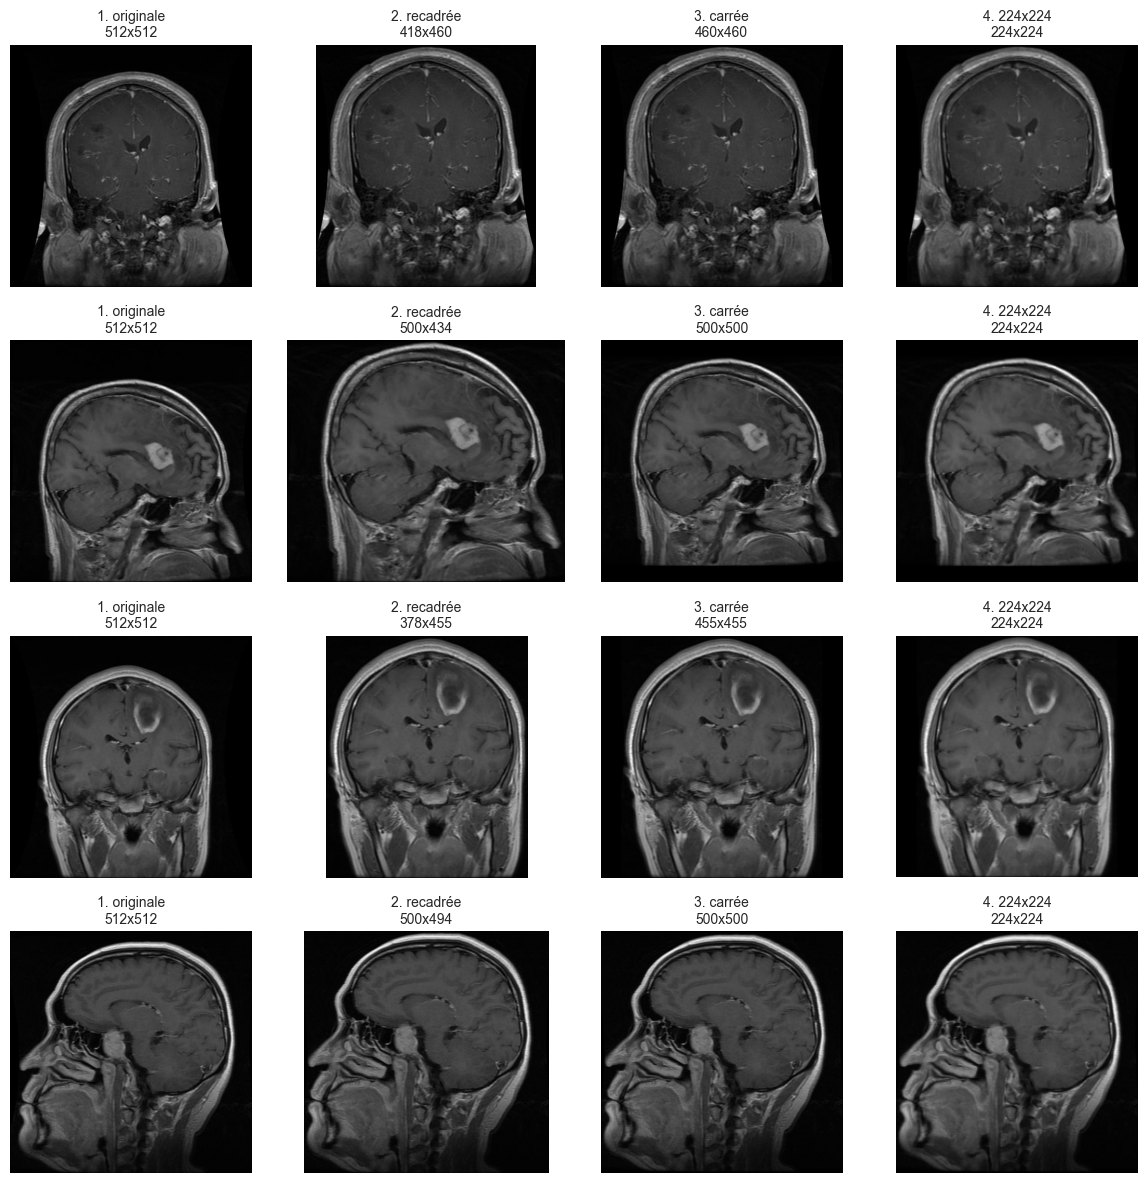

In [2]:
from load_data import CLASS_NAMES, find_dataset_root, list_images, crop_brain, pad_to_square, prepare_image
from utils import load_config

cfg = load_config()["project"]
SIZE = cfg["image_size"]
DATA = find_dataset_root()
paths, labels = list_images(DATA, "Training")

rng = np.random.default_rng(3)
examples = [paths[i] for i in rng.choice(len(paths), 4, replace=False)]
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for r, p in enumerate(examples):
    gray = np.asarray(Image.open(p).convert("L"))
    cropped = crop_brain(gray)
    square = pad_to_square(cropped)
    final = prepare_image(p, SIZE)
    steps = [(gray, "1. originale"), (cropped, "2. recadrée"), (square, "3. carrée"), (final, f"4. {SIZE}x{SIZE}")]
    for c, (img, title) in enumerate(steps):
        axes[r, c].imshow(img, cmap="gray"); axes[r, c].axis("off")
        axes[r, c].set_title(f"{title}\n{img.shape[1]}x{img.shape[0]}", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "preproc_steps.png", dpi=150); plt.show()

## 2. Préparation complète + découpage train / validation / test
Le résultat (images 224×224 en `uint8`) est mis en cache dans `data/processed/`, ce qui évite de relire et redimensionner les JPEG à chaque epoch.

In [3]:
from load_data import prepare_dataset

data = prepare_dataset(SIZE, cfg["val_size"], cfg["seed"])
s = data.stats
print(f"Training brut : {s['n_train_raw']} images, doublons retirés : {s['n_duplicates_removed']}")
split_df = pd.DataFrame({
    name: pd.Series(y).map(dict(enumerate(CLASS_NAMES))).value_counts()
    for name, y in [("train", data.y_train), ("validation", data.y_val), ("test", data.y_test)]
}).loc[CLASS_NAMES]
split_df.loc["Total"] = split_df.sum()
split_df

Training brut : 5600 images, doublons retirés : 171


,train,validation,test
glioma,1190,210,400
meningioma,1178,208,400
notumor,1089,192,400
pituitary,1157,205,400
Total,4614,815,1600


Le découpage est **stratifié** : chaque classe garde la même proportion dans train et validation.
- **train** : apprentissage des poids
- **validation** : callbacks (early stopping, sauvegarde du meilleur modèle) et optimisation des hyperparamètres
- **test** : utilisé **une seule fois**, pour l'évaluation finale (étape 4). Ne jamais l'utiliser pour choisir un modèle, sinon le score de test devient optimiste.

## 3. Normalisation

Statistiques du train (pixels dans [0, 1]) : moyenne = 0.2070, écart-type = 0.1957


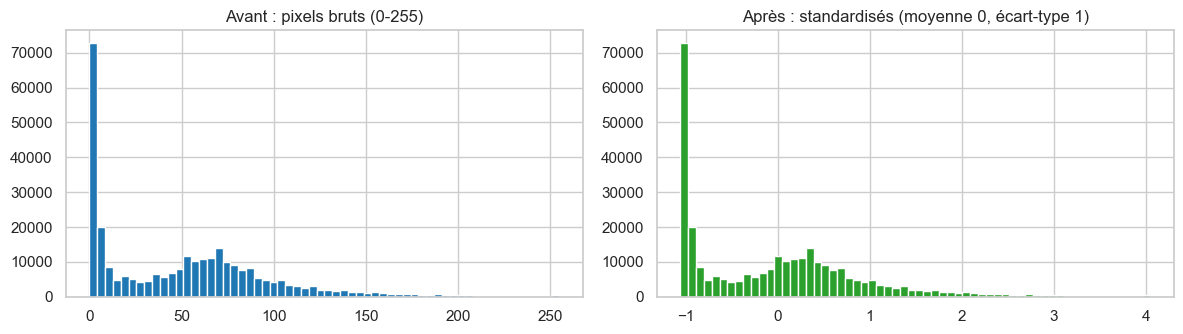

In [4]:
mean, std = s["mean"], s["std"]
print(f"Statistiques du train (pixels dans [0, 1]) : moyenne = {mean:.4f}, écart-type = {std:.4f}")

px = data.x_train[:300].reshape(-1)[::50].astype(np.float32) / 255
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(px * 255, bins=60, color="tab:blue"); axes[0].set_title("Avant : pixels bruts (0-255)")
axes[1].hist((px - mean) / std, bins=60, color="tab:green"); axes[1].set_title("Après : standardisés (moyenne 0, écart-type 1)")
plt.tight_layout(); plt.savefig(FIG / "preproc_normalization.png", dpi=150); plt.show()

- Les statistiques sont calculées **uniquement sur le train**, puis appliquées telles quelles à la validation, au test et aux images de l'application : sinon des informations du test « fuiraient » dans l'entraînement.
- Elles sont enregistrées dans `data/processed/stats.json` pour que l'application Streamlit applique exactement le même prétraitement.
- Le pic à gauche correspond au fond noir, majoritaire sur une IRM.

## 4. Augmentation de données (train uniquement)

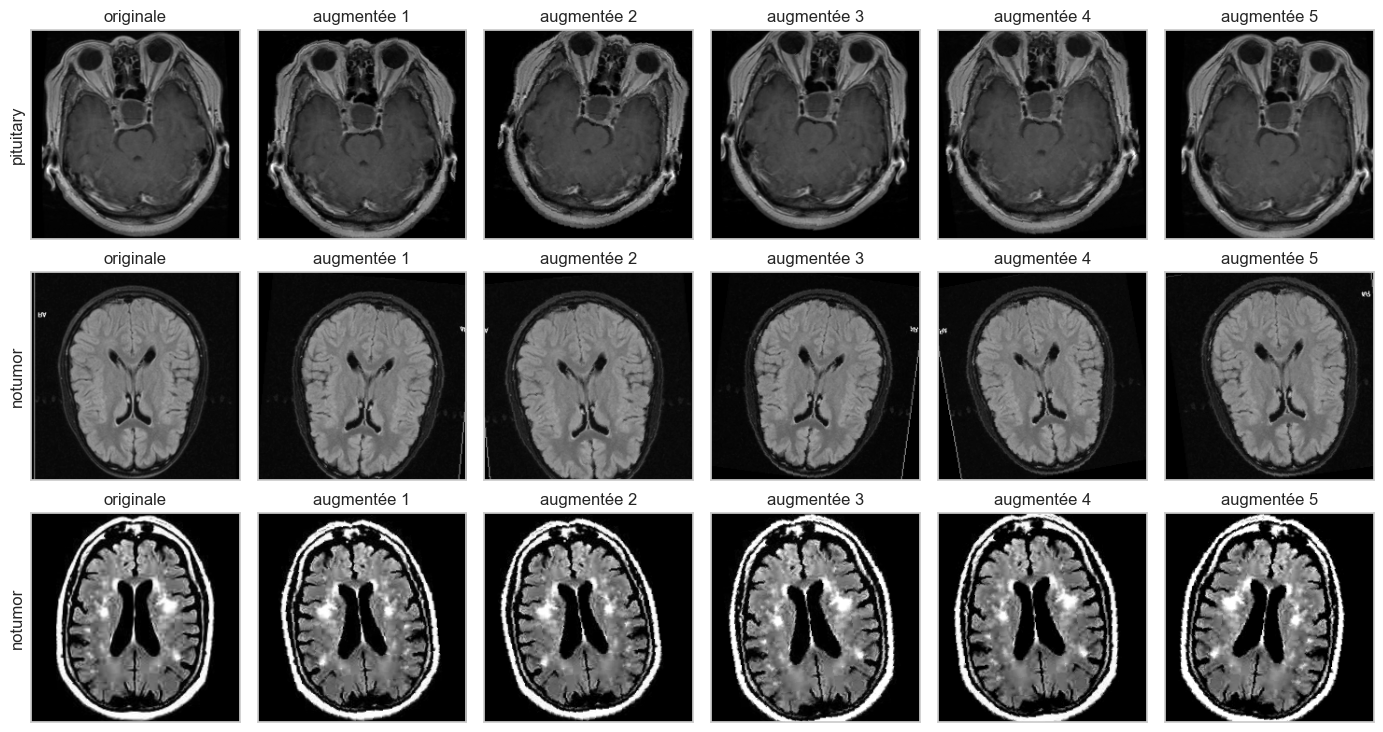

In [5]:
from load_data import MRIDataset

aug = MRIDataset(data.x_train, data.y_train, mean, std, augment=True)
fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
for r, i in enumerate([0, 7, 42]):
    axes[r, 0].imshow(data.x_train[i], cmap="gray"); axes[r, 0].set_title("originale")
    for c in range(1, 6):
        x, _ = aug[i]
        axes[r, c].imshow(x[0], cmap="gray"); axes[r, c].set_title(f"augmentée {c}")
    axes[r, 0].set_ylabel(CLASS_NAMES[data.y_train[i]], fontsize=12)
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(FIG / "preproc_augmentation.png", dpi=150); plt.show()

Augmentations **légères et réalistes** pour une IRM, tirées au hasard à chaque epoch :
- **flip horizontal** : le cerveau est à peu près symétrique gauche/droite, une tumeur peut être d'un côté comme de l'autre (pas de flip vertical : une IRM « à l'envers » n'existe pas)
- **rotation ±10°, translation ±5 %, zoom ±5 %** : variations de position du patient
- **luminosité / contraste ±10 %** : variations entre machines et séquences

Elles augmentent artificiellement la diversité du train et **limitent le surapprentissage**. Elles ne sont **jamais** appliquées à la validation ni au test.

## 5. Vérification des DataLoaders

In [6]:
from load_data import get_dataloaders

train_loader, val_loader, test_loader = get_dataloaders(data, batch_size=32)
x, y = next(iter(train_loader))
print("batch :", tuple(x.shape), x.dtype, "| labels :", y[:10].tolist())
print(f"moyenne du batch = {x.mean():.3f}, écart-type = {x.std():.3f}")
print("batches :", len(train_loader), "train,", len(val_loader), "val,", len(test_loader), "test")

batch : (32, 1, 224, 224) torch.float32 | labels : [1, 0, 1, 0, 2, 1, 3, 0, 1, 2]
moyenne du batch = -0.047, écart-type = 0.964
batches : 145 train, 26 val, 50 test


## Bilan

Les données sont prêtes pour le modèle (étape 2) :
- entrées de forme **(batch, 1, 224, 224)**, standardisées
- 4 classes dans l'ordre `glioma, meningioma, notumor, pituitary` (indices 0 à 3)
- train / validation / test séparés sans fuite d'information

Pour l'application : `load_data.preprocess_for_inference(image_pil, stats)` applique exactement ce pipeline à une nouvelle image.